## Small molecule SMILES to 2D structure and 3D structure

In [6]:
from rdkit import Chem
from rdkit.Chem import AllChem, rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG
import py3Dmol


## Use ketcher-standalone-3.7.0 or higher to sketch the 2D structure of the molecule (free download and open-source)

In [7]:
# ==========================================
# 1. 设置输入 (SMILES)
# ==========================================
# 比如：苯 (c1ccccc1), 乙醇 (CCO), 阿司匹林 (CC(=O)OC1=CC=CC=C1C(=O)O)
# Use ketcher-standalone-3.7.0 or higher to sketch the 2D structure of the molecule
# Paste the Extended SMILES string exported from Ketcher below
smiles_input = "CC(OC1C(C(O)=O)=CC=CC=1)=O"  # 这里放入你要查看的分子的 SMILES 字符串
print(f"当前分子 SMILES: {smiles_input}")


当前分子 SMILES: CC(OC1C(C(O)=O)=CC=CC=1)=O


In [8]:
# ==========================================
# 2. RDKit 生成 3D (使用 MMFF94 力场，速度极快)
# ==========================================
mol = Chem.MolFromSmiles(smiles_input)
if mol is None:
    print("错误：无法从SMILES字符串创建分子！")

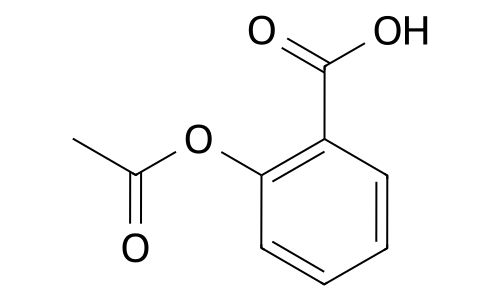

分子式: C9H8O4
原子数: 13
化学键数: 13


In [9]:
# ==========================================
# 3. 绘制化学式
# ==========================================
mol_2d = Chem.RemoveHs(mol)              # 移除显式氢, RDKit 会智能保留需要表达立体化学（手性楔形键）的氢，移除其他杂乱的氢
mol_2d.RemoveAllConformers()             # 清除旧坐标
rdDepictor.SetPreferCoordGen(True)    # 开启 CoordGen (画图更好看)
rdDepictor.Compute2DCoords(mol_2d)       # 生成新坐标

drawer = rdMolDraw2D.MolDraw2DSVG(500, 300) 
opts = drawer.drawOptions()
opts.bondLineWidth = 2.0              # 加粗线条 (这是 ChemDraw 风格的关键)
opts.minFontSize = 14                 # 调整字号
opts.additionalAtomLabelPadding = 0.1 # 增加原子标签留白
opts.useBWAtomPalette()               # 纯黑白 (发表文章推荐)
opts.prepareMolsBeforeDrawing = True 

# 绘制分子式
drawer.DrawMolecule(mol)
drawer.FinishDrawing()
svg_text = drawer.GetDrawingText() 
# 显示与保存
display(SVG(svg_text))
with open('2D_structure.svg', 'w') as f:
    f.write(svg_text)

# 显示分子信息
print(f"分子式: {Chem.rdMolDescriptors.CalcMolFormula(mol)}")
print(f"原子数: {mol.GetNumAtoms()}")
print(f"化学键数: {mol.GetNumBonds()}")

In [10]:
# ==========================================
# 4. 使用 py3Dmol 在 Notebook 中交互式查看结果
# ==========================================
mol_3d = Chem.AddHs(mol)
AllChem.EmbedMolecule(mol_3d)
AllChem.MMFFOptimizeMolecule(mol_3d) # 这步在优化结构，虽然不是量子力学，但长得很像了
xyz = Chem.MolToXYZBlock(mol_3d) # 转为 XYZ 格式
# 创建一个 3D 视窗
view = py3Dmol.view(width=500, height=300, linked=False)
view.addModel(xyz, "xyz")
view.setStyle({'sphere': {'radius': 0.3},  # 原子球体半径
               'stick': {'radius': 0.1}}) 
view.zoomTo()
view.show()

writer = Chem.SDWriter('optimized_structure.sdf')
writer.write(mol_3d)
writer.close() # 记得关闭文件

3Dmol.js failed to load for some reason. Please check your browser console for error messages.